[INFO] Reconstructed and saved train.tsv (8145) & benchmark.tsv (2037).
RUNNING VON HEIJNE 5-FOLD CROSS-VALIDATION (3 Train / 1 Val / 1 Test)
Run 1 [Test=0, Val=1, Train=[2, 3, 4]] | theta*=6.246 | ACC=0.9294 | Sen=0.6875 | PPV=0.6685 | F1=0.6779 | MCC=0.6383
Run 2 [Test=1, Val=2, Train=[3, 4, 0]] | theta*=6.395 | ACC=0.9398 | Sen=0.7386 | PPV=0.7143 | F1=0.7263 | MCC=0.6926
Run 3 [Test=2, Val=3, Train=[4, 0, 1]] | theta*=6.622 | ACC=0.9423 | Sen=0.6989 | PPV=0.7500 | F1=0.7235 | MCC=0.6919
Run 4 [Test=3, Val=4, Train=[0, 1, 2]] | theta*=5.908 | ACC=0.9269 | Sen=0.7727 | PPV=0.6326 | F1=0.6957 | MCC=0.6588
Run 5 [Test=4, Val=0, Train=[1, 2, 3]] | theta*=5.536 | ACC=0.9190 | Sen=0.7955 | PPV=0.5932 | F1=0.6796 | MCC=0.6433

--- 5-Fold Cross-Validation Summary (Mean ± Standard Error, SE = std/sqrt(5)) ---
ACC       : 0.9315 ± 0.0043
Sen       : 0.7386 ± 0.0207
PPV       : 0.6717 ± 0.0280
F1        : 0.7006 ± 0.0104
MCC       : 0.6650 ± 0.0116
ROC_AUC   : 0.9590 ± 0.0037
PR_AUC    : 0.794

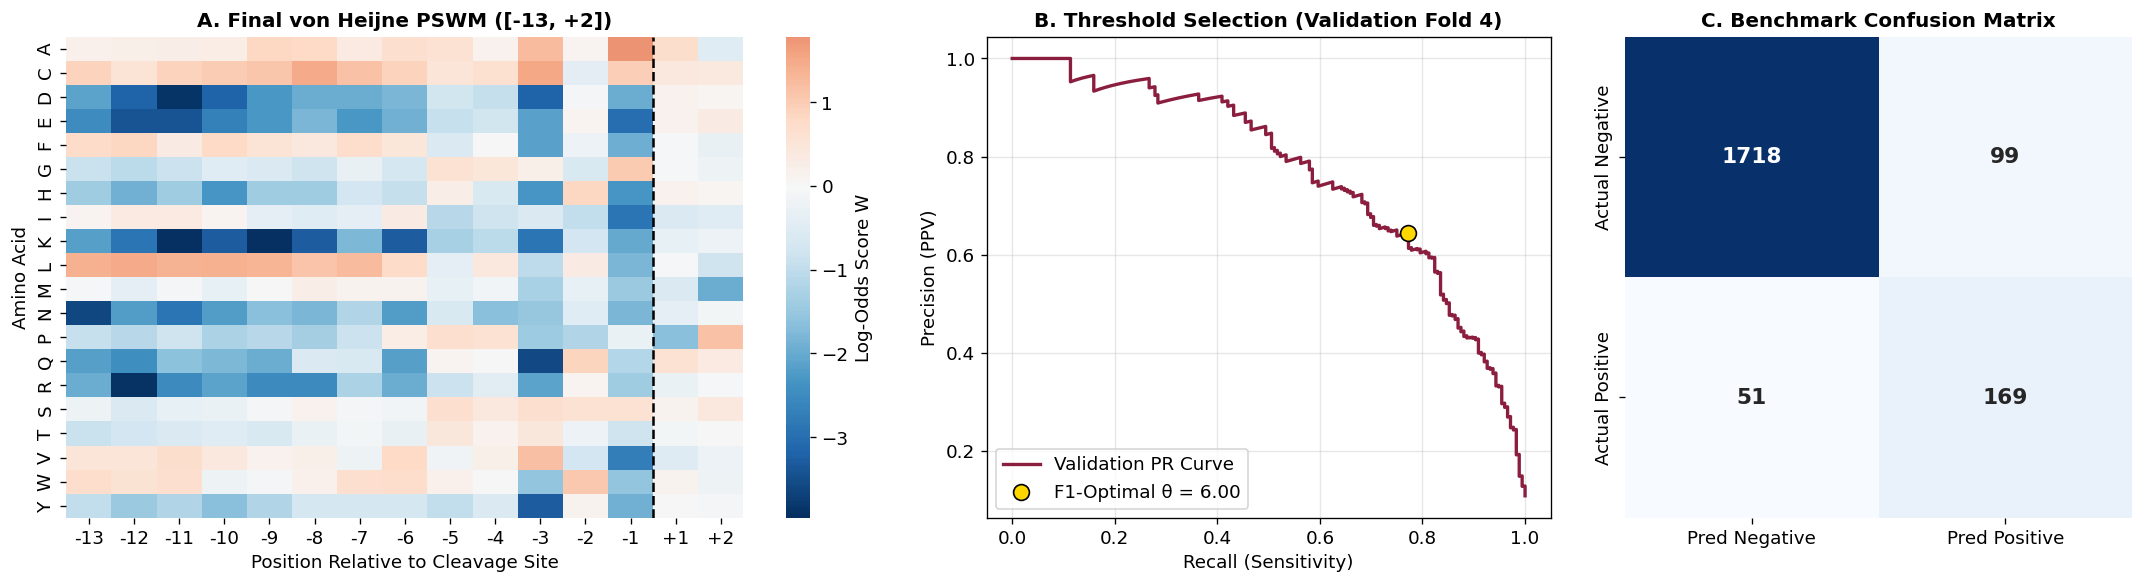


VON HEIJNE BENCHMARK ERROR ANALYSIS (FP TM-Helices, Taxa & FN Motifs)
[FP Analysis] Total Benchmark False Positives (FP)        : 99
[FP Analysis] FPs with N-term TM helix (first 90 aa)      : 60/99 (60.61%)
[FP Analysis] TNs with N-term TM helix (first 90 aa)      : 136/1718 (7.92%)
[FP Analysis] Baseline TM helix rate in Benchmark Negs    : 10.79%
[FP Analysis] Fisher's Exact Test Enrichment Odds Ratio   : 17.90 (p = 2.47e-36)

[Taxonomic Error Distribution across Kingdoms (von Heijne)]
      Kingdom  Total  Pos  Neg  FP  FN  FPR (%)   FNR (%)
      Metazoa   1113  173  940  67  43 7.127660 24.855491
        Fungi    515   22  493  10   4 2.028398 18.181818
Viridiplantae    359   17  342  19   2 5.555556 11.764706
        Other     50    8   42   3   2 7.142857 25.000000

[FN Analysis] Extracted Cleavage Windows: Expected (Train Pos)=879, Benchmark TP=169, Benchmark FN=51


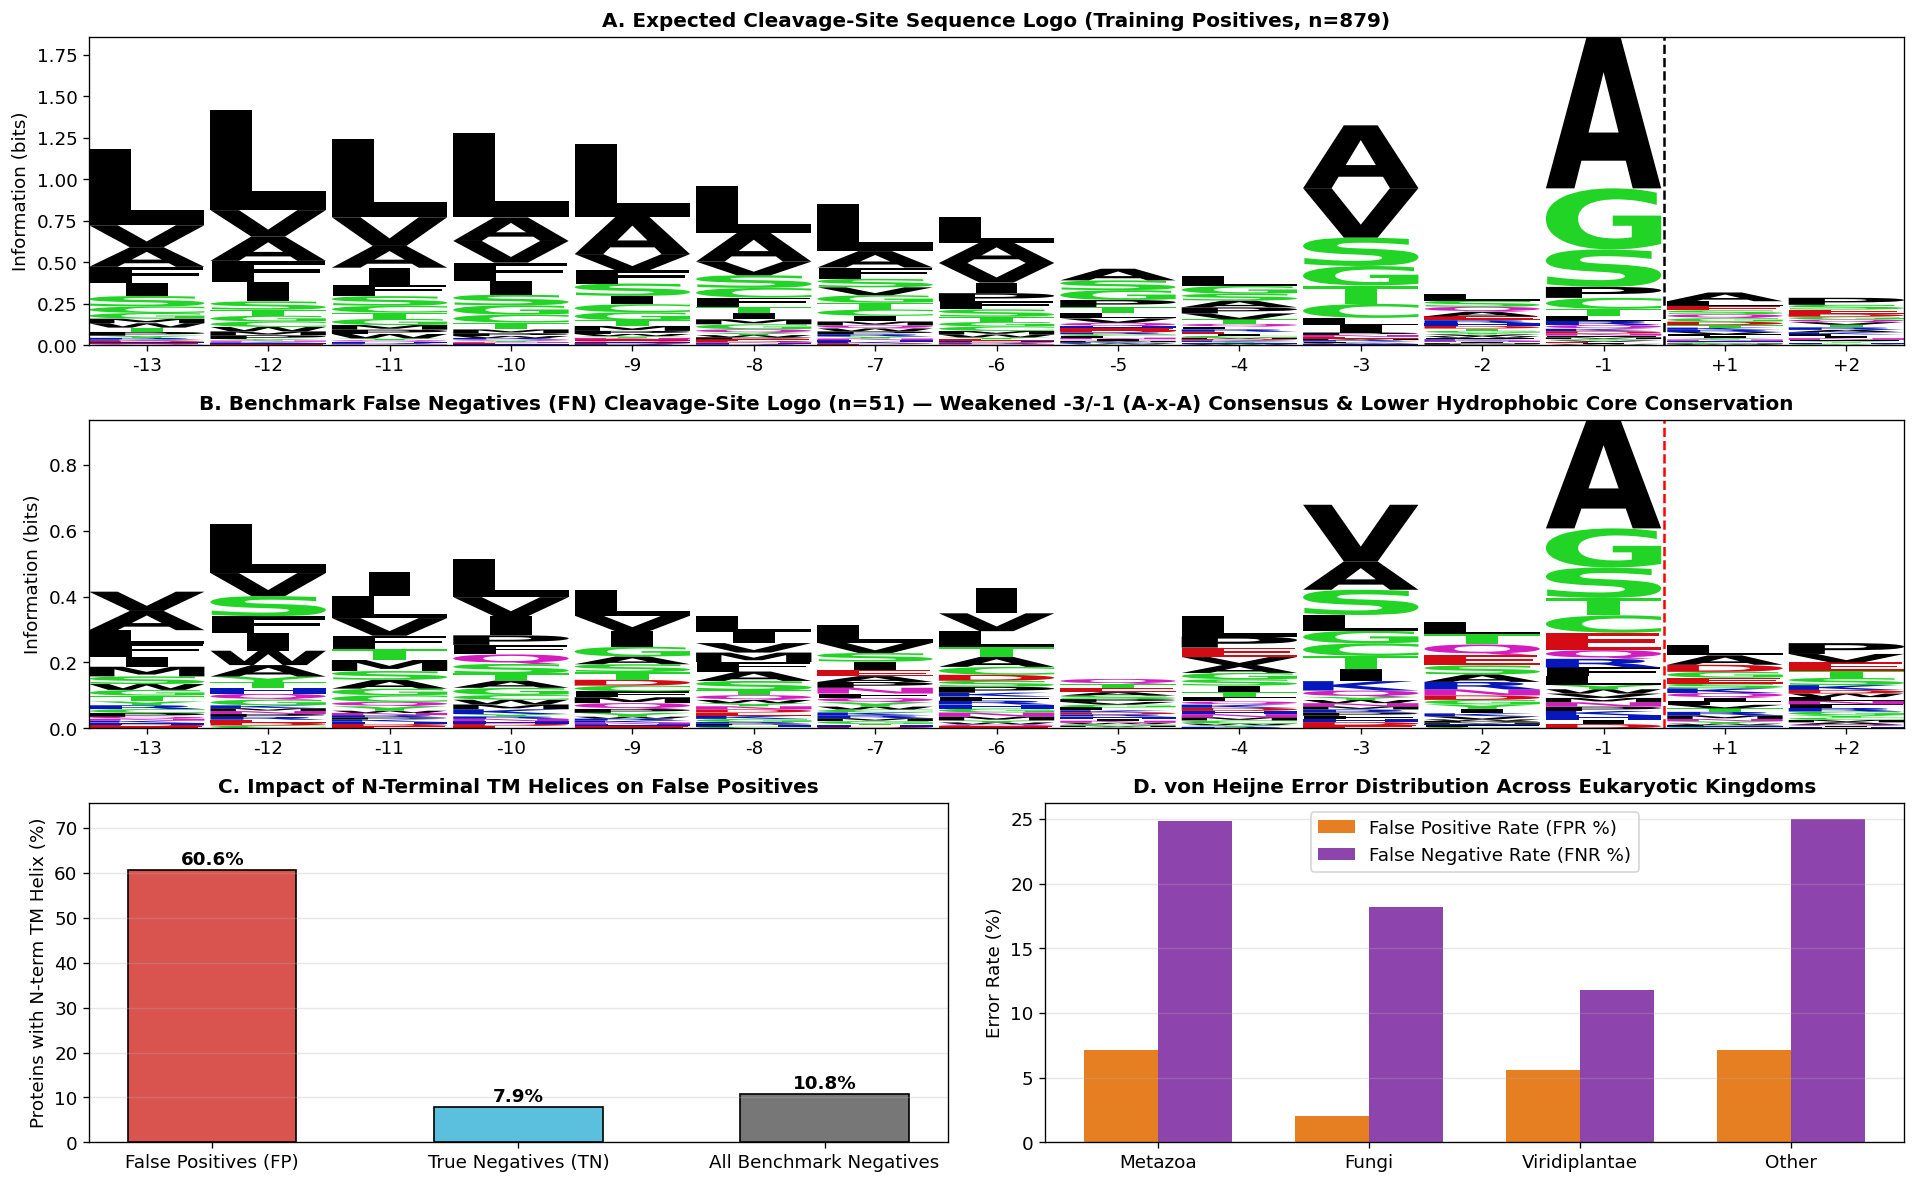

[SUCCESS] Step 4 completed. Figures saved in 'figures/' and metrics in 'results/'.


In [1]:
# ==============================================================================
# STEP 4: THE VON HEIJNE METHOD, FINAL MODELING & ERROR ANALYSIS (2026 EDITION)
# ==============================================================================
import os
import json
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from Bio import SeqIO
from scipy.stats import fisher_exact, mannwhitneyu
from sklearn.metrics import (
    precision_recall_curve, roc_curve, auc, average_precision_score,
    accuracy_score, precision_score, recall_score, f1_score,
    matthews_corrcoef, confusion_matrix
)
from sklearn.model_selection import StratifiedKFold, train_test_split
import logomaker

warnings.filterwarnings("ignore")
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11
})
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

# ------------------------------------------------------------------------------
# 1. SMART DATA LOADER (Finds Step 1 & Step 2 outputs automatically)
# ------------------------------------------------------------------------------
def find_file(filename):
    search_dirs = [
        ".", "..", "../1- Data_Collection", "../2- Data_Preparation",
        os.path.expanduser("~/LB2_Project"), os.path.expanduser("~")
    ]
    for d in search_dirs:
        candidate = os.path.join(d, filename)
        if os.path.exists(candidate):
            return candidate
        matches = glob.glob(os.path.join(d, "**", filename), recursive=True)
        if matches:
            return matches[0]
    raise FileNotFoundError(f"Could not locate '{filename}'. Ensure Step 1 & 2 ran.")

def load_all_project_data():
    pos_tsv_path = find_file("positive.tsv")
    neg_tsv_path = find_file("negative.tsv")
    pos_fa_path  = find_file("positive.fasta")
    neg_fa_path  = find_file("negative.fasta")

    df_pos_raw = pd.read_csv(pos_tsv_path, sep="\t")
    df_neg_raw = pd.read_csv(neg_tsv_path, sep="\t")

    pos_seqs = {rec.id.split("|")[1] if "|" in rec.id else rec.id.split()[0]: str(rec.seq).upper()
                for rec in SeqIO.parse(pos_fa_path, "fasta")}
    neg_seqs = {rec.id.split("|")[1] if "|" in rec.id else rec.id.split()[0]: str(rec.seq).upper()
                for rec in SeqIO.parse(neg_fa_path, "fasta")}
    all_seqs = {**pos_seqs, **neg_seqs}

    # Locate MMseqs2 representative FASTA files from Step 2
    pos_rep_fa = find_file("pos_rep_seq.fasta")
    neg_rep_fa = find_file("neg_rep_seq.fasta")

    pos_rep_ids = {rec.id.split("|")[1] if "|" in rec.id else rec.id.split()[0]
                   for rec in SeqIO.parse(pos_rep_fa, "fasta")}
    neg_rep_ids = {rec.id.split("|")[1] if "|" in rec.id else rec.id.split()[0]
                   for rec in SeqIO.parse(neg_rep_fa, "fasta")}

    df_pos = df_pos_raw[df_pos_raw["Accession"].isin(pos_rep_ids)].copy()
    df_neg = df_neg_raw[df_neg_raw["Accession"].isin(neg_rep_ids)].copy()
    df_pos["label"] = 1
    df_neg["label"] = 0

    # Check if Step 2 already saved train.tsv and benchmark.tsv
    try:
        train_path = find_file("train.tsv")
        bench_path = find_file("benchmark.tsv")
        df_train = pd.read_csv(train_path, sep="\t")
        df_bench = pd.read_csv(bench_path, sep="\t")
        print(f"[INFO] Loaded existing train.tsv ({len(df_train)}) and benchmark.tsv ({len(df_bench)}).")
    except FileNotFoundError:
        # Reconstruct exact 80/20 stratified split & 5-fold CV assignment
        df_all = pd.concat([df_pos, df_neg], ignore_index=True)
        df_train, df_bench = train_test_split(
            df_all, test_size=0.20, stratify=df_all["label"], random_state=42
        )
        df_train = df_train.reset_index(drop=True)
        df_bench = df_bench.reset_index(drop=True)
        skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
        df_train["fold"] = -1
        for fold_idx, (_, val_idx) in enumerate(skf.split(df_train, df_train["label"])):
            df_train.loc[val_idx, "fold"] = fold_idx
        df_train.to_csv("train.tsv", sep="\t", index=False)
        df_bench.to_csv("benchmark.tsv", sep="\t", index=False)
        print(f"[INFO] Reconstructed and saved train.tsv ({len(df_train)}) & benchmark.tsv ({len(df_bench)}).")

    # Normalize column names if needed
    if "class" in df_train.columns and "label" not in df_train.columns:
        df_train["label"] = df_train["class"]
        df_bench["label"] = df_bench["class"]

    # Ensure fold column is 0..4
    if "fold" not in df_train.columns:
        skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
        df_train["fold"] = -1
        for fold_idx, (_, val_idx) in enumerate(skf.split(df_train, df_train["label"])):
            df_train.loc[val_idx, "fold"] = fold_idx

    # Merge full metadata from df_pos and df_neg
    meta_cols_pos = ["Accession", "SP cleavage"]
    meta_cols_neg = ["Accession", "N-term transmembrane"]
    if "SP cleavage" not in df_train.columns:
        df_train = df_train.merge(df_pos[meta_cols_pos], on="Accession", how="left")
        df_bench = df_bench.merge(df_pos[meta_cols_pos], on="Accession", how="left")
    if "N-term transmembrane" not in df_train.columns:
        df_train = df_train.merge(df_neg[meta_cols_neg], on="Accession", how="left")
        df_bench = df_bench.merge(df_neg[meta_cols_neg], on="Accession", how="left")

    df_train["sequence"] = df_train["Accession"].map(all_seqs)
    df_bench["sequence"] = df_bench["Accession"].map(all_seqs)

    return df_train, df_bench, df_pos, df_neg, all_seqs

df_train, df_bench, df_filtered_pos, df_filtered_neg, all_seqs = load_all_project_data()

# ------------------------------------------------------------------------------
# 2. VON HEIJNE METHOD PARAMETERS & FUNCTIONS ([-13, +2], Pseudocount=1)
# ------------------------------------------------------------------------------
AA_ORDER = list("ACDEFGHIKLMNPQRSTVWY")
AA_TO_IDX = {aa: idx for idx, aa in enumerate(AA_ORDER)}

# SwissProt empirical amino-acid composition (UniProtKB/Swiss-Prot statistics)
SWISSPROT_BG = {
    'A': 0.0825, 'R': 0.0553, 'N': 0.0406, 'D': 0.0545, 'C': 0.0137,
    'Q': 0.0393, 'E': 0.0675, 'G': 0.0707, 'H': 0.0227, 'I': 0.0596,
    'L': 0.0966, 'K': 0.0584, 'M': 0.0242, 'F': 0.0386, 'P': 0.0470,
    'S': 0.0656, 'T': 0.0534, 'W': 0.0108, 'Y': 0.0292, 'V': 0.0687
}
# Normalize to sum to exactly 1.0
bg_sum = sum(SWISSPROT_BG.values())
BG_VEC = np.array([SWISSPROT_BG[aa] / bg_sum for aa in AA_ORDER])

WINDOW_BEFORE = 13  # -13 to -1
WINDOW_AFTER  = 2   # +1 to +2
WINDOW_SIZE   = WINDOW_BEFORE + WINDOW_AFTER  # 15 residues
SCAN_NTERM    = 90  # Scan first 90 N-terminal residues (positions 1..76)
POS_LABELS    = [f"{i}" for i in range(-13, 0)] + ["+1", "+2"]

def build_pswm(df_positives):
    """
    Builds Position-Specific Weight Matrix (PSWM) from aligned [-13, +2] cleavage contexts.
    Uses pseudocounts of 1 and SwissProt background frequencies.
    """
    counts = np.ones((20, WINDOW_SIZE), dtype=np.float64)  # Pseudocount = 1
    valid_n = 0

    for _, row in df_positives.iterrows():
        seq = row["sequence"]
        if pd.isna(row["SP cleavage"]) or not isinstance(seq, str):
            continue
        c = int(row["SP cleavage"])
        start, end = c - WINDOW_BEFORE, c + WINDOW_AFTER
        if 0 <= start and end <= len(seq):
            window = seq[start:end]
            if len(window) == WINDOW_SIZE and all(aa in AA_TO_IDX for aa in window):
                for j, aa in enumerate(window):
                    counts[AA_TO_IDX[aa], j] += 1.0
                valid_n += 1

    # Probability matrix PSPM: divide by (N + 20)
    pspm = counts / (valid_n + 20.0)
    # Weight matrix PSWM: log-odds vs SwissProt background
    pswm = np.log(pspm / BG_VEC[:, None])
    return pswm, pspm, valid_n

def score_sequence_vh(seq, pswm, max_nterm=SCAN_NTERM):
    """
    Scans the first 90 N-terminal residues with the 15-residue PSWM.
    Returns (max_score, best_cleavage_site_index).
    """
    nterm = seq[:max_nterm]
    n_windows = len(nterm) - WINDOW_SIZE + 1
    if n_windows <= 0:
        return -np.inf, -1

    best_score = -np.inf
    best_cleavage = -1
    for start in range(n_windows):
        fragment = nterm[start:start + WINDOW_SIZE]
        score = 0.0
        for j, aa in enumerate(fragment):
            idx = AA_TO_IDX.get(aa, -1)
            if idx != -1:
                score += pswm[idx, j]
            else:
                score += 0.0  # Ambiguous residue (e.g. X) neutral log-odds
        if score > best_score:
            best_score = score
            best_cleavage = start + WINDOW_BEFORE
    return best_score, best_cleavage

def score_dataset_vh(df, pswm):
    scores, cleavages = [], []
    for seq in df["sequence"]:
        s, c = score_sequence_vh(seq, pswm)
        scores.append(s)
        cleavages.append(c)
    return np.array(scores), np.array(cleavages)

def find_optimal_f1_threshold(y_true, y_scores):
    precision, recall, thresholds = precision_recall_curve(y_true, y_scores)
    # precision and recall have length len(thresholds) + 1
    prec_t, rec_t = precision[:-1], recall[:-1]
    f1_scores = np.divide(
        2 * prec_t * rec_t, prec_t + rec_t,
        out=np.zeros_like(prec_t), where=(prec_t + rec_t) > 0
    )
    best_idx = np.argmax(f1_scores)
    return thresholds[best_idx], f1_scores[best_idx], precision, recall, thresholds

def compute_binary_metrics(y_true, y_pred, y_scores=None):
    metrics = {
        "ACC": accuracy_score(y_true, y_pred),
        "PPV": precision_score(y_true, y_pred, zero_division=0),
        "Sen": recall_score(y_true, y_pred, zero_division=0),
        "F1":  f1_score(y_true, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_true, y_pred)
    }
    if y_scores is not None:
        fpr, tpr, _ = roc_curve(y_true, y_scores)
        metrics["ROC_AUC"] = auc(fpr, tpr)
        metrics["PR_AUC"]  = average_precision_score(y_true, y_scores)
    return metrics

# ------------------------------------------------------------------------------
# 3. 5-FOLD CROSS-VALIDATION (Exact Rotation from 2026 Lecture Slide 24)
# ------------------------------------------------------------------------------
print("=" * 75)
print("RUNNING VON HEIJNE 5-FOLD CROSS-VALIDATION (3 Train / 1 Val / 1 Test)")
print("=" * 75)

cv_records = []
for j in range(5):
    test_fold = j
    val_fold  = (j + 1) % 5
    trn_folds = [(i + j) % 5 for i in range(2, 5)]

    df_trn_cv  = df_train[df_train["fold"].isin(trn_folds)]
    df_val_cv  = df_train[df_train["fold"] == val_fold]
    df_tst_cv  = df_train[df_train["fold"] == test_fold]

    # 1. Estimate PSWM W on positive sequences of the 3 training folds
    pswm_cv, _, n_pos_trn = build_pswm(df_trn_cv[df_trn_cv["label"] == 1])

    # 2. Pick optimal threshold theta on the validation fold via PR curve
    val_scores, _ = score_dataset_vh(df_val_cv, pswm_cv)
    opt_theta, val_f1, _, _, _ = find_optimal_f1_threshold(df_val_cv["label"].values, val_scores)

    # 3. Classify the test fold using chosen threshold
    tst_scores, _ = score_dataset_vh(df_tst_cv, pswm_cv)
    tst_preds = (tst_scores >= opt_theta).astype(int)

    m = compute_binary_metrics(df_tst_cv["label"].values, tst_preds, tst_scores)
    m["Run"] = j + 1
    m["Test_Fold"] = test_fold
    m["Val_Fold"] = val_fold
    m["Threshold"] = opt_theta
    cv_records.append(m)
    print(f"Run {j+1} [Test={test_fold}, Val={val_fold}, Train={trn_folds}] | "
          f"theta*={opt_theta:.3f} | ACC={m['ACC']:.4f} | Sen={m['Sen']:.4f} | "
          f"PPV={m['PPV']:.4f} | F1={m['F1']:.4f} | MCC={m['MCC']:.4f}")

df_cv_vh = pd.DataFrame(cv_records)
print("\n--- 5-Fold Cross-Validation Summary (Mean ± Standard Error, SE = std/sqrt(5)) ---")
vh_cv_summary = {}
for metric in ["ACC", "Sen", "PPV", "F1", "MCC", "ROC_AUC", "PR_AUC", "Threshold"]:
    mean_val = df_cv_vh[metric].mean()
    se_val   = df_cv_vh[metric].std(ddof=1) / np.sqrt(5)
    vh_cv_summary[metric] = {"mean": float(mean_val), "se": float(se_val)}
    print(f"{metric:10s}: {mean_val:.4f} ± {se_val:.4f}")

# ------------------------------------------------------------------------------
# 4. FINAL VON HEIJNE MODEL TRAINING & BENCHMARK EVALUATION (2026 Protocol)
#    Slide 2 & 3 of 05-Benchmarking:
#    1. Train matrix on positives of folds {0, 1, 2, 3}
#    2. Fix final decision threshold on validation fold {4}
#    3. Retrain matrix on the WHOLE training set (folds {0, 1, 2, 3, 4})
#    4. Test once on the hold-out Benchmarking set
# ------------------------------------------------------------------------------
print("\n" + "=" * 75)
print("TRAINING FINAL VON HEIJNE PREDICTOR & TESTING ON BENCHMARK SET")
print("=" * 75)

# Step 1 & 2: Folds 0-3 for matrix, Fold 4 for validation threshold
df_trn_sub = df_train[df_train["fold"].isin([0, 1, 2, 3])]
df_val_sub = df_train[df_train["fold"] == 4]

pswm_sub, _, _ = build_pswm(df_trn_sub[df_trn_sub["label"] == 1])
val_sub_scores, _ = score_dataset_vh(df_val_sub, pswm_sub)
final_theta_vh, val_sub_f1, pr_prec, pr_rec, pr_thresh = find_optimal_f1_threshold(
    df_val_sub["label"].values, val_sub_scores
)

# Step 3: Retrain PSWM on the WHOLE training set (all 5 folds)
pswm_final, pspm_final, n_train_pos_total = build_pswm(df_train[df_train["label"] == 1])

# Step 4: Test once on the Benchmarking set
bench_scores_vh, bench_cleavages_vh = score_dataset_vh(df_bench, pswm_final)
bench_preds_vh = (bench_scores_vh >= final_theta_vh).astype(int)
bench_labels   = df_bench["label"].values

vh_bench_metrics = compute_binary_metrics(bench_labels, bench_preds_vh, bench_scores_vh)
print(f"Final Decision Threshold (fixed on Fold 4) : {final_theta_vh:.4f}")
print(f"Retrained PSWM Total Positive Sequences    : {n_train_pos_total}")
print("\n--- Hold-Out Benchmarking Set Performance (von Heijne) ---")
for k, v in vh_bench_metrics.items():
    print(f"{k:10s}: {v:.4f}")

# Plot PSWM Heatmap + Validation PR Curve + Benchmark Confusion Matrix
fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={"width_ratios": [1.5, 1, 0.9]})

# Panel A: Final PSWM Heatmap
sns.heatmap(
    pswm_final, ax=axes[0], cmap="RdBu_r", center=0,
    xticklabels=POS_LABELS, yticklabels=AA_ORDER, cbar_kws={"label": "Log-Odds Score W"}
)
axes[0].axvline(WINDOW_BEFORE, color="black", linestyle="--", lw=1.5)
axes[0].set_title("A. Final von Heijne PSWM ([-13, +2])", fontweight="bold")
axes[0].set_xlabel("Position Relative to Cleavage Site")
axes[0].set_ylabel("Amino Acid")

# Panel B: Precision-Recall Curve on Validation Fold 4
axes[1].plot(pr_rec, pr_prec, color="#8B1E3F", lw=2, label="Validation PR Curve")
best_idx = np.argmin(np.abs(pr_thresh - final_theta_vh))
axes[1].scatter(pr_rec[best_idx], pr_prec[best_idx], color="gold", edgecolor="black",
                s=90, zorder=5, label=f"F1-Optimal θ = {final_theta_vh:.2f}")
axes[1].set_title("B. Threshold Selection (Validation Fold 4)", fontweight="bold")
axes[1].set_xlabel("Recall (Sensitivity)")
axes[1].set_ylabel("Precision (PPV)")
axes[1].legend(loc="lower left")
axes[1].grid(alpha=0.3)

# Panel C: Benchmark Confusion Matrix
cm_vh = confusion_matrix(bench_labels, bench_preds_vh)
sns.heatmap(
    cm_vh, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[2],
    xticklabels=["Pred Negative", "Pred Positive"],
    yticklabels=["Actual Negative", "Actual Positive"],
    annot_kws={"size": 13, "weight": "bold"}
)
axes[2].set_title("C. Benchmark Confusion Matrix", fontweight="bold")

plt.tight_layout()
plt.savefig("figures/fig4_1_von_heijne_summary.png", bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------------------
# 5. QUALITATIVE ERROR ANALYSIS ON BENCHMARKING SET (2026 Lecture 05)
# ------------------------------------------------------------------------------
print("\n" + "=" * 75)
print("VON HEIJNE BENCHMARK ERROR ANALYSIS (FP TM-Helices, Taxa & FN Motifs)")
print("=" * 75)

df_bench_vh = df_bench.copy()
df_bench_vh["vh_score"] = bench_scores_vh
df_bench_vh["vh_pred"]  = bench_preds_vh
df_bench_vh["vh_cleavage_pred"] = bench_cleavages_vh

# Categorize outcomes: TP, TN, FP, FN
conditions = [
    (df_bench_vh["label"] == 1) & (df_bench_vh["vh_pred"] == 1),
    (df_bench_vh["label"] == 0) & (df_bench_vh["vh_pred"] == 0),
    (df_bench_vh["label"] == 0) & (df_bench_vh["vh_pred"] == 1),
    (df_bench_vh["label"] == 1) & (df_bench_vh["vh_pred"] == 0),
]
df_bench_vh["outcome"] = np.select(conditions, ["TP", "TN", "FP", "FN"], default="Other")
df_bench_vh.to_csv("results/vh_benchmark_predictions.tsv", sep="\t", index=False)

# --- 5A. False Positives Analysis: N-terminal Transmembrane Helix Fraction ---
bench_neg = df_bench_vh[df_bench_vh["label"] == 0].copy()
bench_neg["N-term transmembrane"] = bench_neg["N-term transmembrane"].astype(bool)

fp_df = bench_neg[bench_neg["vh_pred"] == 1]
tn_df = bench_neg[bench_neg["vh_pred"] == 0]

fp_tm_count = int(fp_df["N-term transmembrane"].sum())
fp_total    = len(fp_df)
fp_tm_frac  = (fp_tm_count / fp_total * 100) if fp_total > 0 else 0.0

tn_tm_count = int(tn_df["N-term transmembrane"].sum())
tn_total    = len(tn_df)
tn_tm_frac  = (tn_tm_count / tn_total * 100) if tn_total > 0 else 0.0

overall_neg_tm_frac = bench_neg["N-term transmembrane"].mean() * 100

# Fisher's Exact Test for TM helix enrichment in FPs vs TNs
contingency_tm = [[fp_tm_count, fp_total - fp_tm_count],
                  [tn_tm_count, tn_total - tn_tm_count]]
odds_ratio_tm, p_val_tm = fisher_exact(contingency_tm)

print(f"[FP Analysis] Total Benchmark False Positives (FP)        : {fp_total}")
print(f"[FP Analysis] FPs with N-term TM helix (first 90 aa)      : {fp_tm_count}/{fp_total} ({fp_tm_frac:.2f}%)")
print(f"[FP Analysis] TNs with N-term TM helix (first 90 aa)      : {tn_tm_count}/{tn_total} ({tn_tm_frac:.2f}%)")
print(f"[FP Analysis] Baseline TM helix rate in Benchmark Negs    : {overall_neg_tm_frac:.2f}%")
print(f"[FP Analysis] Fisher's Exact Test Enrichment Odds Ratio   : {odds_ratio_tm:.2f} (p = {p_val_tm:.2e})")

# --- 5B. Taxonomic (Kingdom & Species) Distribution of Errors ---
kingdom_stats = []
for k_name, grp in df_bench_vh.groupby("Kingdom"):
    n_pos = (grp["label"] == 1).sum()
    n_neg = (grp["label"] == 0).sum()
    n_fp  = (grp["outcome"] == "FP").sum()
    n_fn  = (grp["outcome"] == "FN").sum()
    fpr_k = (n_fp / n_neg * 100) if n_neg > 0 else 0.0
    fnr_k = (n_fn / n_pos * 100) if n_pos > 0 else 0.0
    kingdom_stats.append({
        "Kingdom": k_name, "Total": len(grp), "Pos": n_pos, "Neg": n_neg,
        "FP": n_fp, "FN": n_fn, "FPR (%)": fpr_k, "FNR (%)": fnr_k
    })
df_kingdom_vh = pd.DataFrame(kingdom_stats).sort_values("Total", ascending=False)
print("\n[Taxonomic Error Distribution across Kingdoms (von Heijne)]")
print(df_kingdom_vh.to_string(index=False))

# --- 5C. False Negatives Analysis: Cleavage-Site Sequence Logo Comparison ---
def extract_valid_windows(df_subset):
    windows = []
    for _, row in df_subset.iterrows():
        seq = row["sequence"]
        if pd.isna(row["SP cleavage"]) or not isinstance(seq, str):
            continue
        c = int(row["SP cleavage"])
        s, e = c - WINDOW_BEFORE, c + WINDOW_AFTER
        if 0 <= s and e <= len(seq):
            w = seq[s:e]
            if len(w) == WINDOW_SIZE and all(aa in AA_TO_IDX for aa in w):
                windows.append(w)
    return windows

train_pos_windows = extract_valid_windows(df_train[df_train["label"] == 1])
bench_tp_windows  = extract_valid_windows(df_bench_vh[df_bench_vh["outcome"] == "TP"])
bench_fn_windows  = extract_valid_windows(df_bench_vh[df_bench_vh["outcome"] == "FN"])

print(f"\n[FN Analysis] Extracted Cleavage Windows: "
      f"Expected (Train Pos)={len(train_pos_windows)}, "
      f"Benchmark TP={len(bench_tp_windows)}, Benchmark FN={len(bench_fn_windows)}")

fig = plt.figure(figsize=(16, 10))
gs  = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1.1])

# Logo 1: Expected Cleavage-Site Context (Training Positives)
ax_logo_exp = fig.add_subplot(gs[0, :])
info_exp = logomaker.alignment_to_matrix(train_pos_windows, to_type="information")
logomaker.Logo(info_exp, ax=ax_logo_exp, color_scheme="weblogo_protein")
ax_logo_exp.axvline(WINDOW_BEFORE - 0.5, color="black", linestyle="--", lw=1.5)
ax_logo_exp.set_xticks(range(WINDOW_SIZE))
ax_logo_exp.set_xticklabels(POS_LABELS)
ax_logo_exp.set_ylabel("Information (bits)")
ax_logo_exp.set_title(f"A. Expected Cleavage-Site Sequence Logo (Training Positives, n={len(train_pos_windows)})",
                      fontweight="bold")

# Logo 2: Benchmark False Negatives (FN) Cleavage-Site Context
ax_logo_fn = fig.add_subplot(gs[1, :])
if len(bench_fn_windows) > 0:
    info_fn = logomaker.alignment_to_matrix(bench_fn_windows, to_type="information")
    logomaker.Logo(info_fn, ax=ax_logo_fn, color_scheme="weblogo_protein")
    ax_logo_fn.axvline(WINDOW_BEFORE - 0.5, color="red", linestyle="--", lw=1.5)
    ax_logo_fn.set_xticks(range(WINDOW_SIZE))
    ax_logo_fn.set_xticklabels(POS_LABELS)
    ax_logo_fn.set_ylabel("Information (bits)")
    ax_logo_fn.set_title(f"B. Benchmark False Negatives (FN) Cleavage-Site Logo (n={len(bench_fn_windows)}) — "
                         f"Weakened -3/-1 (A-x-A) Consensus & Lower Hydrophobic Core Conservation",
                         fontweight="bold")

# Panel C: TM-Helix Fraction in FPs vs TNs
ax_tm = fig.add_subplot(gs[2, 0])
bars = ax_tm.bar(
    ["False Positives (FP)", "True Negatives (TN)", "All Benchmark Negatives"],
    [fp_tm_frac, tn_tm_frac, overall_neg_tm_frac],
    color=["#D9534F", "#5BC0DE", "#777777"], edgecolor="black", width=0.55
)
for b in bars:
    ax_tm.text(b.get_x() + b.get_width()/2, b.get_height() + 1.2,
               f"{b.get_height():.1f}%", ha="center", fontweight="bold")
ax_tm.set_ylim(0, max(fp_tm_frac + 15, 40))
ax_tm.set_ylabel("Proteins with N-term TM Helix (%)")
ax_tm.set_title("C. Impact of N-Terminal TM Helices on False Positives", fontweight="bold")
ax_tm.grid(axis="y", alpha=0.3)

# Panel D: Taxonomic Error Rates (FPR & FNR by Kingdom)
ax_tax = fig.add_subplot(gs[2, 1])
x_k = np.arange(len(df_kingdom_vh))
w_k = 0.35
ax_tax.bar(x_k - w_k/2, df_kingdom_vh["FPR (%)"], width=w_k, label="False Positive Rate (FPR %)", color="#E67E22")
ax_tax.bar(x_k + w_k/2, df_kingdom_vh["FNR (%)"], width=w_k, label="False Negative Rate (FNR %)", color="#8E44AD")
ax_tax.set_xticks(x_k)
ax_tax.set_xticklabels(df_kingdom_vh["Kingdom"])
ax_tax.set_ylabel("Error Rate (%)")
ax_tax.set_title("D. von Heijne Error Distribution Across Eukaryotic Kingdoms", fontweight="bold")
ax_tax.legend()
ax_tax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("figures/fig4_2_von_heijne_error_analysis.png", bbox_inches="tight")
plt.show()

# Save summary JSON for Step 5 & 6 comparison
with open("results/vh_summary.json", "w") as f:
    json.dump({
        "cv_summary": vh_cv_summary,
        "final_threshold": float(final_theta_vh),
        "benchmark_metrics": {k: float(v) for k, v in vh_bench_metrics.items()},
        "error_analysis": {
            "fp_total": fp_total,
            "fp_tm_count": fp_tm_count,
            "fp_tm_percent": float(fp_tm_frac),
            "tn_tm_percent": float(tn_tm_frac),
            "tm_odds_ratio": float(odds_ratio_tm),
            "tm_fisher_p": float(p_val_tm),
            "fn_total": len(bench_fn_windows)
        }
    }, f, indent=2)
print("[SUCCESS] Step 4 completed. Figures saved in 'figures/' and metrics in 'results/'.")